In [2]:
!pip install xgboost catboost lightgbm shap joblib -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.8 MB/s eta 0:00:00


In [3]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os

os.listdir("/content/drive/MyDrive/Lifestyle AI/Dataset")

['Sleep_health_and_lifestyle_dataset.csv',
 'world_health_data.csv',
 'health_lifestyle_dataset.csv',
 'Obesity prediction.csv',
 'sleep_processed.csv',
 'obesity_processed.csv',
 'health_processed.csv']

In [6]:
sleep = pd.read_csv("/content/drive/MyDrive/Lifestyle AI/Dataset/Sleep_health_and_lifestyle_dataset.csv")

health = pd.read_csv("/content/drive/MyDrive/Lifestyle AI/Dataset/health_lifestyle_dataset.csv")

obesity = pd.read_csv("/content/drive/MyDrive/Lifestyle AI/Dataset/Obesity prediction.csv")

world = pd.read_csv("/content/drive/MyDrive/Lifestyle AI/Dataset/world_health_data.csv")

In [7]:
print("Sleep Shape :",sleep.shape)

print("Health Shape :",health.shape)

print("Obesity Shape :",obesity.shape)

print("World Shape :",world.shape)

Sleep Shape : (374, 13)
Health Shape : (100000, 16)
Obesity Shape : (2111, 17)
World Shape : (6650, 12)


In [8]:
sleep.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [9]:
health.head()

,id,age,gender,bmi,daily_steps,sleep_hours,water_intake_l,calories_consumed,smoker,alcohol,resting_hr,systolic_bp,diastolic_bp,cholesterol,family_history,disease_risk
0,1,56,Male,20.5,4198,3.9,3.4,1602,0,0,97,161,111,240,0,0
1,2,69,Female,33.3,14359,9.0,4.7,2346,0,1,68,116,65,207,0,0
2,3,46,Male,31.6,1817,6.6,4.2,1643,0,1,90,123,99,296,0,0
3,4,32,Female,38.2,15772,3.6,2.0,2460,0,0,71,165,95,175,0,0
4,5,60,Female,33.6,6037,3.8,4.0,3756,0,1,98,139,61,294,0,0


In [10]:
obesity.head()

,Gender,Age,Height,Weight,family_history,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,Obesity
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [11]:
world.head()

,country,country_code,year,health_exp,life_expect,maternal_mortality,infant_mortality,neonatal_mortality,under_5_mortality,prev_hiv,inci_tuberc,prev_undernourishment
0,Aruba,ABW,1999,NaN,73.561000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,1999,NaN,51.258874,NaN,88.285642,38.433841,142.506373,6.684793,NaN,NaN
2,Afghanistan,AFG,1999,NaN,54.846000,NaN,94.600000,64.000000,135.800000,0.100000,NaN,NaN
3,Africa Western and Central,AFW,1999,NaN,49.726429,NaN,101.541373,44.733554,173.943151,NaN,NaN,NaN
4,Angola,AGO,1999,NaN,45.386000,NaN,123.500000,51.000000,208.000000,1.300000,NaN,NaN


In [12]:
print(sleep.columns)

Index(['Person ID', 'Gender', 'Age', 'Occupation', 'Sleep Duration',
       'Quality of Sleep', 'Physical Activity Level', 'Stress Level',
       'BMI Category', 'Blood Pressure', 'Heart Rate', 'Daily Steps',
       'Sleep Disorder'],
      dtype='object')


In [13]:
print(health.columns)

Index(['id', 'age', 'gender', 'bmi', 'daily_steps', 'sleep_hours',
       'water_intake_l', 'calories_consumed', 'smoker', 'alcohol',
       'resting_hr', 'systolic_bp', 'diastolic_bp', 'cholesterol',
       'family_history', 'disease_risk'],
      dtype='object')


In [14]:
print(obesity.columns)

Index(['Gender', 'Age', 'Height', 'Weight', 'family_history', 'FAVC', 'FCVC',
       'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS',
       'Obesity'],
      dtype='object')


In [15]:
print(world.columns)

Index(['country', 'country_code', 'year', 'health_exp', 'life_expect',
       'maternal_mortality', 'infant_mortality', 'neonatal_mortality',
       'under_5_mortality', 'prev_hiv', 'inci_tuberc',
       'prev_undernourishment'],
      dtype='object')


In [16]:
sleep.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


In [17]:
health.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 100000 non-null  int64  
 1   age                100000 non-null  int64  
 2   gender             100000 non-null  object 
 3   bmi                100000 non-null  float64
 4   daily_steps        100000 non-null  int64  
 5   sleep_hours        100000 non-null  float64
 6   water_intake_l     100000 non-null  float64
 7   calories_consumed  100000 non-null  int64  
 8   smoker             100000 non-null  int64  
 9   alcohol            100000 non-null  int64  
 10  resting_hr         100000 non-null  int64  
 11  systolic_bp        100000 non-null  int64  
 12  diastolic_bp       100000 non-null  int64  
 13  cholesterol        100000 non-null  int64  
 14  family_history     100000 non-null  int64  
 15  disease_risk       100000 non-null  int64  
dtypes: 

In [18]:
obesity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Gender          2111 non-null   object 
 1   Age             2111 non-null   float64
 2   Height          2111 non-null   float64
 3   Weight          2111 non-null   float64
 4   family_history  2111 non-null   object 
 5   FAVC            2111 non-null   object 
 6   FCVC            2111 non-null   float64
 7   NCP             2111 non-null   float64
 8   CAEC            2111 non-null   object 
 9   SMOKE           2111 non-null   object 
 10  CH2O            2111 non-null   float64
 11  SCC             2111 non-null   object 
 12  FAF             2111 non-null   float64
 13  TUE             2111 non-null   float64
 14  CALC            2111 non-null   object 
 15  MTRANS          2111 non-null   object 
 16  Obesity         2111 non-null   object 
dtypes: float64(8), object(9)
memory u

In [19]:
world.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6650 entries, 0 to 6649
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   country                6650 non-null   object 
 1   country_code           6650 non-null   object 
 2   year                   6650 non-null   int64  
 3   health_exp             5167 non-null   float64
 4   life_expect            6190 non-null   float64
 5   maternal_mortality     4893 non-null   float64
 6   infant_mortality       5856 non-null   float64
 7   neonatal_mortality     5856 non-null   float64
 8   under_5_mortality      5856 non-null   float64
 9   prev_hiv               4270 non-null   float64
 10  inci_tuberc            5429 non-null   float64
 11  prev_undernourishment  4805 non-null   float64
dtypes: float64(9), int64(1), object(2)
memory usage: 623.6+ KB


In [20]:
sleep.isnull().sum()

,0
Person ID,0
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Blood Pressure,0


In [21]:
health.isnull().sum()

,0
id,0
age,0
gender,0
bmi,0
daily_steps,0
sleep_hours,0
water_intake_l,0
calories_consumed,0
smoker,0
alcohol,0


In [22]:
obesity.isnull().sum()

,0
Gender,0
Age,0
Height,0
Weight,0
family_history,0
FAVC,0
FCVC,0
NCP,0
CAEC,0
SMOKE,0


In [23]:
world.isnull().sum()

,0
country,0
country_code,0
year,0
health_exp,1483
life_expect,460
maternal_mortality,1757
infant_mortality,794
neonatal_mortality,794
under_5_mortality,794
prev_hiv,2380


In [24]:
#Custom dataset creation

In [25]:
sleep_df = sleep.copy()

health_df = health.copy()

obesity_df = obesity.copy()

In [26]:
print("Sleep :",sleep_df.shape)

print("Health :",health_df.shape)

print("Obesity :",obesity_df.shape)

Sleep : (374, 13)
Health : (100000, 16)
Obesity : (2111, 17)


In [27]:
sleep_df.rename(columns={

"Person ID":"id",

"Gender":"gender",

"Age":"age",

"Sleep Duration":"sleep_hours",

"Physical Activity Level":"physical_activity",

"Stress Level":"stress_level",

"Heart Rate":"heart_rate",

"Daily Steps":"daily_steps",

"Blood Pressure":"blood_pressure",

"BMI Category":"bmi_category",

"Sleep Disorder":"sleep_disorder"

},inplace=True)

In [28]:
obesity_df.rename(columns={

"Gender":"gender",

"Age":"age",

"Height":"height",

"Weight":"weight",

"family_history":"family_history",

"SMOKE":"smoker",

"CH2O":"water_intake",

"FAF":"physical_activity_score",

"CALC":"alcohol",

"Obesity":"obesity_class"

},inplace=True)

In [29]:

sleep_df = sleep_df[[

"gender",

"age",

"sleep_hours",

"physical_activity",

"stress_level",

"heart_rate",

"daily_steps",

"blood_pressure",

"bmi_category"

]]

In [30]:
health_df = health_df[[

"gender",

"age",

"bmi",

"daily_steps",

"sleep_hours",

"water_intake_l",

"calories_consumed",

"smoker",

"alcohol",

"resting_hr",

"systolic_bp",

"diastolic_bp",

"cholesterol",

"family_history",

"disease_risk"

]]

In [31]:
obesity_df = obesity_df[[

"gender",

"age",

"height",

"weight",

"family_history",

"smoker",

"water_intake",

"physical_activity_score",

"alcohol",

"obesity_class"

]]

In [32]:
print(sleep_df.head())

  gender  age  sleep_hours  physical_activity  stress_level  heart_rate  \
0   Male   27          6.1                 42             6          77   
1   Male   28          6.2                 60             8          75   
2   Male   28          6.2                 60             8          75   
3   Male   28          5.9                 30             8          85   
4   Male   28          5.9                 30             8          85   

   daily_steps blood_pressure bmi_category  
0         4200         126/83   Overweight  
1        10000         125/80       Normal  
2        10000         125/80       Normal  
3         3000         140/90        Obese  
4         3000         140/90        Obese  


In [33]:
print(health_df.head())

   gender  age   bmi  daily_steps  sleep_hours  water_intake_l  \
0    Male   56  20.5         4198          3.9             3.4   
1  Female   69  33.3        14359          9.0             4.7   
2    Male   46  31.6         1817          6.6             4.2   
3  Female   32  38.2        15772          3.6             2.0   
4  Female   60  33.6         6037          3.8             4.0   

   calories_consumed  smoker  alcohol  resting_hr  systolic_bp  diastolic_bp  \
0               1602       0        0          97          161           111   
1               2346       0        1          68          116            65   
2               1643       0        1          90          123            99   
3               2460       0        0          71          165            95   
4               3756       0        1          98          139            61   

   cholesterol  family_history  disease_risk  
0          240               0             0  
1          207              

In [34]:
print(obesity_df.head())

   gender   age  height  weight family_history smoker  water_intake  \
0  Female  21.0    1.62    64.0            yes     no           2.0   
1  Female  21.0    1.52    56.0            yes    yes           3.0   
2    Male  23.0    1.80    77.0            yes     no           2.0   
3    Male  27.0    1.80    87.0             no     no           2.0   
4    Male  22.0    1.78    89.8             no     no           2.0   

   physical_activity_score     alcohol        obesity_class  
0                      0.0          no        Normal_Weight  
1                      3.0   Sometimes        Normal_Weight  
2                      2.0  Frequently        Normal_Weight  
3                      2.0  Frequently   Overweight_Level_I  
4                      0.0   Sometimes  Overweight_Level_II  


In [35]:
common=set(sleep_df.columns)

common=common.intersection(set(health_df.columns))

common=common.intersection(set(obesity_df.columns))

print(common)

{'age', 'gender'}


In [36]:
print(len(sleep_df))

print(len(health_df))

print(len(obesity_df))

374
100000
2111


In [37]:
sleep_df.to_csv("/content/drive/MyDrive/Lifestyle AI/Dataset/sleep_processed.csv",index=False)

health_df.to_csv("/content/drive/MyDrive/Lifestyle AI/Dataset/health_processed.csv",index=False)

obesity_df.to_csv("/content/drive/MyDrive/Lifestyle AI/Dataset/obesity_processed.csv",index=False)

print("Saved Successfully!")

Saved Successfully!


In [38]:
#only using health dataset cuz we've got all the parameters in it

In [39]:

df = health.copy()

print(df.shape)

df.head()

(100000, 16)


,id,age,gender,bmi,daily_steps,sleep_hours,water_intake_l,calories_consumed,smoker,alcohol,resting_hr,systolic_bp,diastolic_bp,cholesterol,family_history,disease_risk
0,1,56,Male,20.5,4198,3.9,3.4,1602,0,0,97,161,111,240,0,0
1,2,69,Female,33.3,14359,9.0,4.7,2346,0,1,68,116,65,207,0,0
2,3,46,Male,31.6,1817,6.6,4.2,1643,0,1,90,123,99,296,0,0
3,4,32,Female,38.2,15772,3.6,2.0,2460,0,0,71,165,95,175,0,0
4,5,60,Female,33.6,6037,3.8,4.0,3756,0,1,98,139,61,294,0,0


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 100000 non-null  int64  
 1   age                100000 non-null  int64  
 2   gender             100000 non-null  object 
 3   bmi                100000 non-null  float64
 4   daily_steps        100000 non-null  int64  
 5   sleep_hours        100000 non-null  float64
 6   water_intake_l     100000 non-null  float64
 7   calories_consumed  100000 non-null  int64  
 8   smoker             100000 non-null  int64  
 9   alcohol            100000 non-null  int64  
 10  resting_hr         100000 non-null  int64  
 11  systolic_bp        100000 non-null  int64  
 12  diastolic_bp       100000 non-null  int64  
 13  cholesterol        100000 non-null  int64  
 14  family_history     100000 non-null  int64  
 15  disease_risk       100000 non-null  int64  
dtypes: 

In [41]:
df.isnull().sum()

,0
id,0
age,0
gender,0
bmi,0
daily_steps,0
sleep_hours,0
water_intake_l,0
calories_consumed,0
smoker,0
alcohol,0


In [42]:
print(df.duplicated().sum())

0


In [43]:
df=df.drop_duplicates()

print(df.shape)

(100000, 16)


In [44]:
df.describe()

,id,age,bmi,daily_steps,sleep_hours,water_intake_l,calories_consumed,smoker,alcohol,resting_hr,systolic_bp,diastolic_bp,cholesterol,family_history,disease_risk
count,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000
mean,50000.500000,48.525990,29.024790,10479.87029,6.491784,2.751496,2603.341200,0.200940,0.300020,74.457420,134.58063,89.508850,224.300630,0.299150,0.248210
std,28867.657797,17.886768,6.352666,5483.63236,2.021922,1.297338,807.288563,0.400705,0.458269,14.423715,25.95153,17.347041,43.327749,0.457888,0.431976
min,1.000000,18.000000,18.000000,1000.00000,3.000000,0.500000,1200.000000,0.000000,0.000000,50.000000,90.00000,60.000000,150.000000,0.000000,0.000000
25%,25000.750000,33.000000,23.500000,5729.00000,4.700000,1.600000,1906.000000,0.000000,0.000000,62.000000,112.00000,74.000000,187.000000,0.000000,0.000000
50%,50000.500000,48.000000,29.000000,10468.00000,6.500000,2.800000,2603.000000,0.000000,0.000000,74.000000,135.00000,89.000000,224.000000,0.000000,0.000000
75%,75000.250000,64.000000,34.500000,15229.00000,8.200000,3.900000,3299.000000,0.000000,1.000000,87.000000,157.00000,105.000000,262.000000,1.000000,0.000000
max,100000.000000,79.000000,40.000000,19999.00000,10.000000,5.000000,3999.000000,1.000000,1.000000,99.000000,179.00000,119.000000,299.000000,1.000000,1.000000


In [45]:
df.columns.tolist()

['id',
 'age',
 'gender',
 'bmi',
 'daily_steps',
 'sleep_hours',
 'water_intake_l',
 'calories_consumed',
 'smoker',
 'alcohol',
 'resting_hr',
 'systolic_bp',
 'diastolic_bp',
 'cholesterol',
 'family_history',
 'disease_risk']

In [46]:
df["disease_risk"].value_counts()

,count
disease_risk,
0,75179
1,24821


In [47]:
df["disease_risk"].value_counts(normalize=True)*100

,proportion
disease_risk,
0,75.179
1,24.821


In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.figsize"]=(8,5)

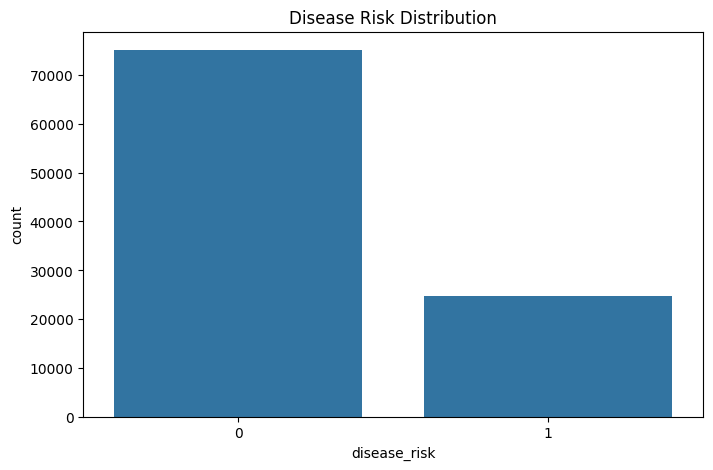

In [49]:
sns.countplot(x="disease_risk",data=df)

plt.title("Disease Risk Distribution")

plt.show()

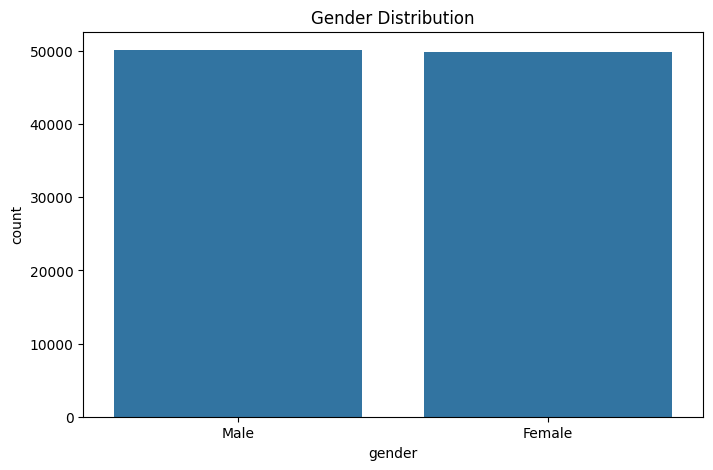

In [50]:
sns.countplot(x="gender",data=df)

plt.title("Gender Distribution")

plt.show()

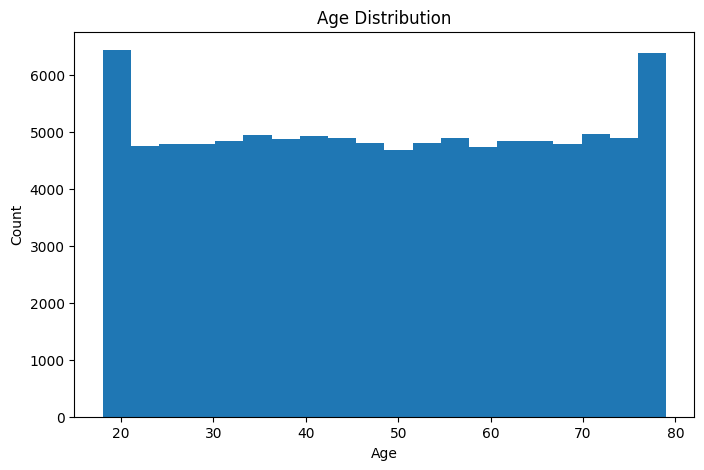

In [51]:
plt.hist(df["age"],bins=20)

plt.title("Age Distribution")

plt.xlabel("Age")

plt.ylabel("Count")

plt.show()

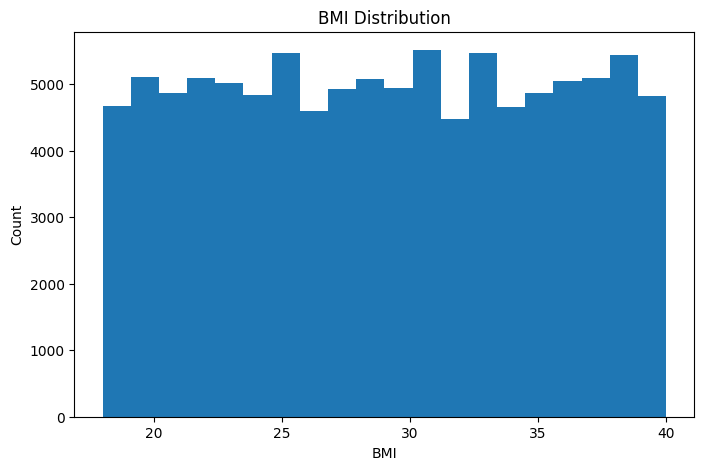

In [52]:
plt.hist(df["bmi"],bins=20)

plt.title("BMI Distribution")

plt.xlabel("BMI")

plt.ylabel("Count")

plt.show()

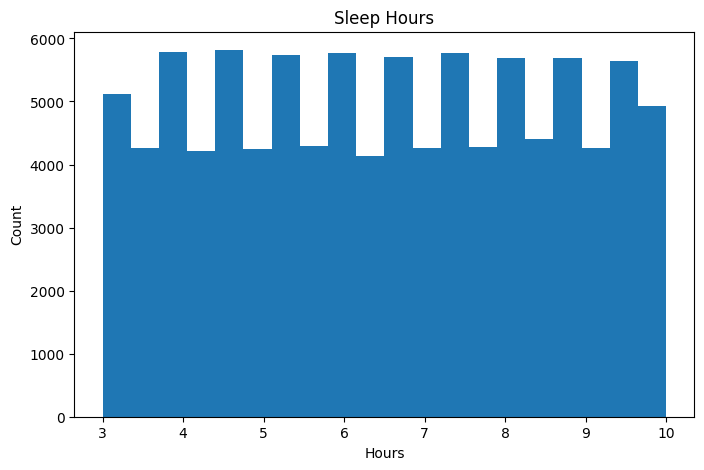

In [53]:
plt.hist(df["sleep_hours"],bins=20)

plt.title("Sleep Hours")

plt.xlabel("Hours")

plt.ylabel("Count")

plt.show()

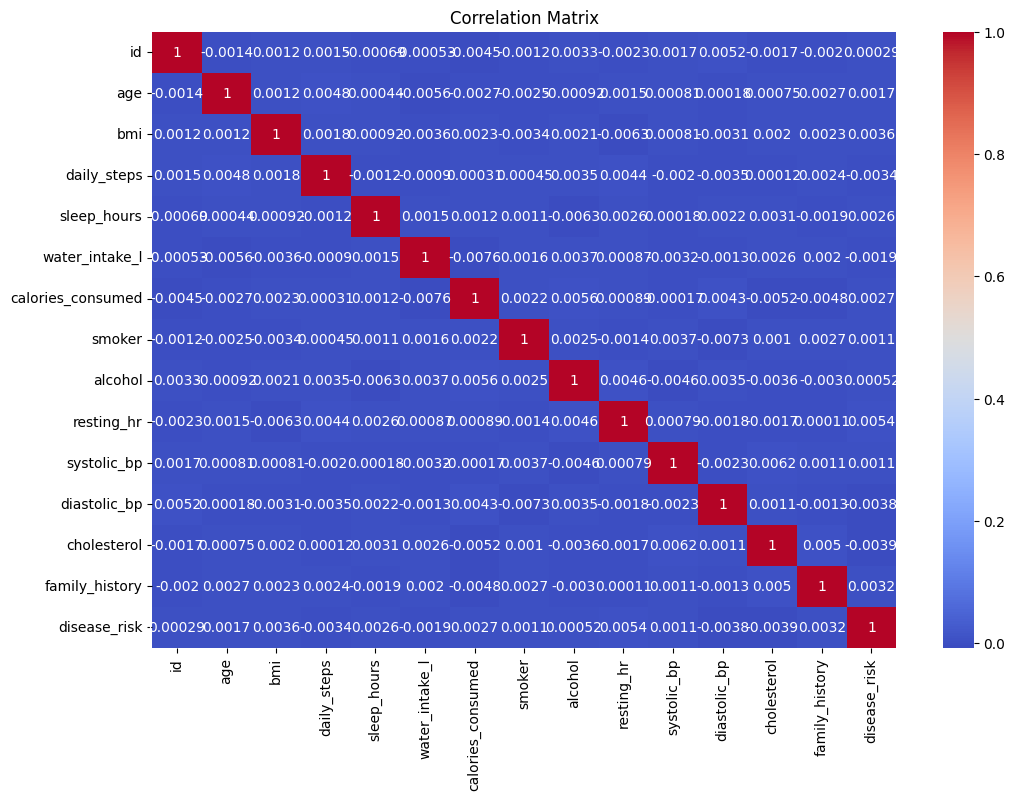

In [54]:
numeric=df.select_dtypes(include=["int64","float64"])

corr=numeric.corr()

plt.figure(figsize=(12,8))

sns.heatmap(corr,
            annot=True,
            cmap="coolwarm")

plt.title("Correlation Matrix")

plt.show()

In [55]:
df.dtypes

,0
id,int64
age,int64
gender,object
bmi,float64
daily_steps,int64
sleep_hours,float64
water_intake_l,float64
calories_consumed,int64
smoker,int64
alcohol,int64


In [56]:

from sklearn.preprocessing import LabelEncoder

gender_encoder = LabelEncoder()

df["gender"] = gender_encoder.fit_transform(df["gender"])

In [57]:
target_encoder = LabelEncoder()

df["disease_risk"] = target_encoder.fit_transform(df["disease_risk"])

In [58]:
print(df.head())

   id  age  gender   bmi  daily_steps  sleep_hours  water_intake_l  \
0   1   56       1  20.5         4198          3.9             3.4   
1   2   69       0  33.3        14359          9.0             4.7   
2   3   46       1  31.6         1817          6.6             4.2   
3   4   32       0  38.2        15772          3.6             2.0   
4   5   60       0  33.6         6037          3.8             4.0   

   calories_consumed  smoker  alcohol  resting_hr  systolic_bp  diastolic_bp  \
0               1602       0        0          97          161           111   
1               2346       0        1          68          116            65   
2               1643       0        1          90          123            99   
3               2460       0        0          71          165            95   
4               3756       0        1          98          139            61   

   cholesterol  family_history  disease_risk  
0          240               0             0  
1   

In [59]:
X = df.drop("disease_risk", axis=1)

y = df["disease_risk"]

In [60]:
print(X.shape)

print(y.shape)

(100000, 15)
(100000,)


In [61]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42,

    stratify=y

)

In [62]:
print(X_train.shape)

print(X_test.shape)

print(y_train.shape)

print(y_test.shape)

(80000, 15)
(20000, 15)
(80000,)
(20000,)


In [63]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [64]:
print("Training completed preprocessing!")

print(X_train.shape)

Training completed preprocessing!
(80000, 15)


In [65]:
X = df.drop("disease_risk", axis=1)
y = df["disease_risk"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [66]:
!pip install xgboost catboost lightgbm -q

In [67]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import VotingClassifier

from sklearn.neural_network import MLPClassifier

from lightgbm import LGBMClassifier

from xgboost import XGBClassifier

from catboost import CatBoostClassifier

In [68]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score

results=[]

In [69]:
gb=GradientBoostingClassifier(random_state=42)

gb.fit(X_train,y_train)

pred=gb.predict(X_test)

acc=accuracy_score(y_test,pred)

pre=precision_score(y_test,pred,average="weighted")

rec=recall_score(y_test,pred,average="weighted")

f1=f1_score(y_test,pred,average="weighted")

results.append(["Gradient Boosting",acc,pre,rec,f1])

print(acc)

0.75175


In [70]:
xgb=XGBClassifier(

random_state=42,

eval_metric="logloss"

)

xgb.fit(X_train,y_train)

pred=xgb.predict(X_test)

acc=accuracy_score(y_test,pred)

pre=precision_score(y_test,pred,average="weighted")

rec=recall_score(y_test,pred,average="weighted")

f1=f1_score(y_test,pred,average="weighted")

results.append(["XGBoost",acc,pre,rec,f1])

print(acc)

0.74695


In [71]:
cat=CatBoostClassifier(

verbose=False,

random_state=42

)

cat.fit(X_train,y_train)

pred=cat.predict(X_test)

acc=accuracy_score(y_test,pred)

pre=precision_score(y_test,pred,average="weighted")

rec=recall_score(y_test,pred,average="weighted")

f1=f1_score(y_test,pred,average="weighted")

results.append(["CatBoost",acc,pre,rec,f1])

print(acc)

0.75145


In [72]:
rf=RandomForestClassifier(

random_state=42

)

rf.fit(X_train,y_train)

pred=rf.predict(X_test)

acc=accuracy_score(y_test,pred)

pre=precision_score(y_test,pred,average="weighted")

rec=recall_score(y_test,pred,average="weighted")

f1=f1_score(y_test,pred,average="weighted")

results.append(["Random Forest",acc,pre,rec,f1])

print(acc)

0.7517


In [73]:
et=ExtraTreesClassifier(

random_state=42

)

et.fit(X_train,y_train)

pred=et.predict(X_test)

acc=accuracy_score(y_test,pred)

pre=precision_score(y_test,pred,average="weighted")

rec=recall_score(y_test,pred,average="weighted")

f1=f1_score(y_test,pred,average="weighted")

results.append(["Extra Trees",acc,pre,rec,f1])

print(acc)

0.7517


In [74]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

X_train_scaled=scaler.fit_transform(X_train)

X_test_scaled=scaler.transform(X_test)

mlp=MLPClassifier(

random_state=42,

max_iter=300

)

mlp.fit(X_train_scaled,y_train)

pred=mlp.predict(X_test_scaled)

acc=accuracy_score(y_test,pred)

pre=precision_score(y_test,pred,average="weighted")

rec=recall_score(y_test,pred,average="weighted")

f1=f1_score(y_test,pred,average="weighted")

results.append(["MLP",acc,pre,rec,f1])

print(acc)

0.75105


In [75]:
results_df=pd.DataFrame(

results,

columns=[

"Model",

"Accuracy",

"Precision",

"Recall",

"F1 Score"

]

)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Gradient Boosting,0.75175,0.565194,0.75175,0.645258
1,XGBoost,0.74695,0.622686,0.74695,0.646690
2,CatBoost,0.75145,0.648004,0.75145,0.645766
3,Random Forest,0.75170,0.565185,0.75170,0.645234
4,Extra Trees,0.75170,0.627254,0.75170,0.645328
5,MLP,0.75105,0.579682,0.75105,0.645009


In [76]:
results_df=results_df.sort_values(

by="Accuracy",

ascending=False

)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Gradient Boosting,0.75175,0.565194,0.75175,0.645258
3,Random Forest,0.75170,0.565185,0.75170,0.645234
4,Extra Trees,0.75170,0.627254,0.75170,0.645328
2,CatBoost,0.75145,0.648004,0.75145,0.645766
5,MLP,0.75105,0.579682,0.75105,0.645009
1,XGBoost,0.74695,0.622686,0.74695,0.646690


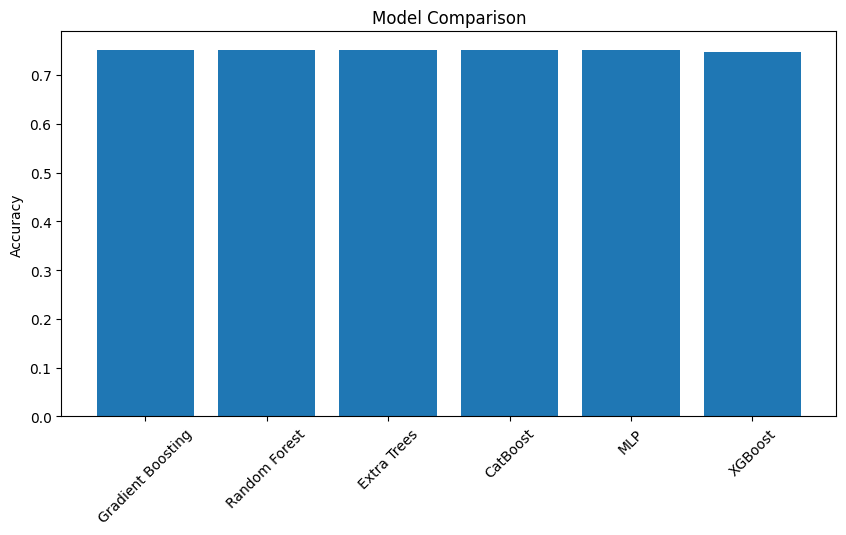

In [77]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.bar(

results_df["Model"],

results_df["Accuracy"]

)

plt.xticks(rotation=45)

plt.title("Model Comparison")

plt.ylabel("Accuracy")

plt.show()

In [78]:
best_model=results_df.iloc[0]["Model"]

print(best_model)

Gradient Boosting


In [79]:
results_df.to_csv(

"Model_Comparison.csv",

index=False

)

In [80]:
from sklearn.metrics import classification_report

pred = gb.predict(X_test)

print(classification_report(y_test,pred))

              precision    recall  f1-score   support

           0       0.75      1.00      0.86     15036
           1       0.00      0.00      0.00      4964

    accuracy                           0.75     20000
   macro avg       0.38      0.50      0.43     20000
weighted avg       0.57      0.75      0.65     20000



In [81]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test,pred)

print(cm)

[[15035     1]
 [ 4964     0]]


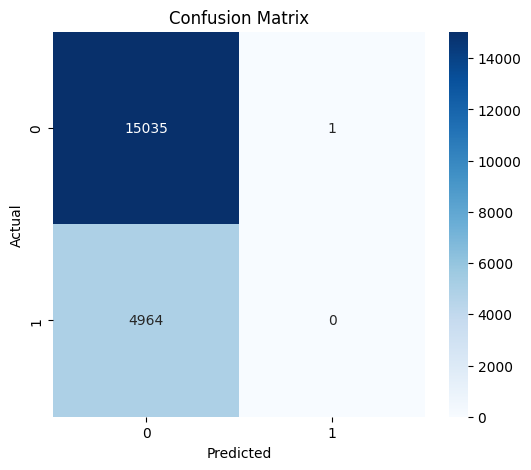

In [82]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

In [83]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test,pred)

0.75175

In [84]:
from sklearn.metrics import precision_score

precision_score(
    y_test,
    pred,
    average="weighted"
)

0.5651939096954848

In [85]:
from sklearn.metrics import recall_score

recall_score(
    y_test,
    pred,
    average="weighted"
)

0.75175

In [86]:
from sklearn.metrics import f1_score

f1_score(
    y_test,
    pred,
    average="weighted"
)

0.6452583416583416

In [87]:
print(df["disease_risk"].unique())

print(df["disease_risk"].nunique())

[0 1]
2


In [88]:
y_prob = gb.predict_proba(X_test)[:,1]

In [89]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

roc_auc = auc(fpr, tpr)

print("AUC Score :",roc_auc)

AUC Score : 0.4969894506742776


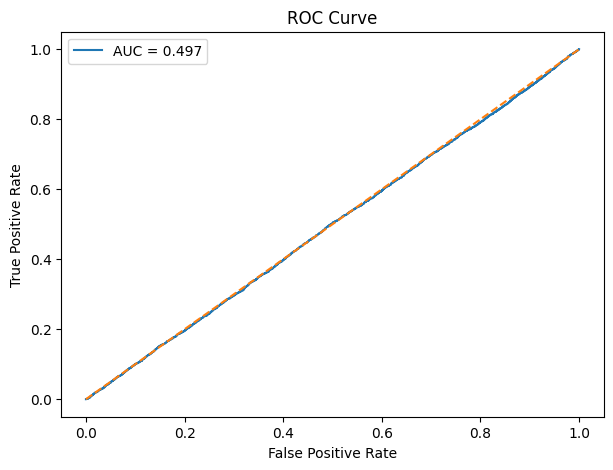

In [90]:
plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    label="AUC = %0.3f"%roc_auc
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

In [91]:
importance = pd.DataFrame({

"Feature":X.columns,

"Importance":gb.feature_importances_

})

importance=importance.sort_values(

by="Importance",

ascending=False

)

importance.head(10)

,Feature,Importance
4,daily_steps,0.186636
0,id,0.136655
7,calories_consumed,0.125643
3,bmi,0.106218
11,systolic_bp,0.101569
13,cholesterol,0.085425
5,sleep_hours,0.065256
12,diastolic_bp,0.055275
10,resting_hr,0.050705
1,age,0.042019


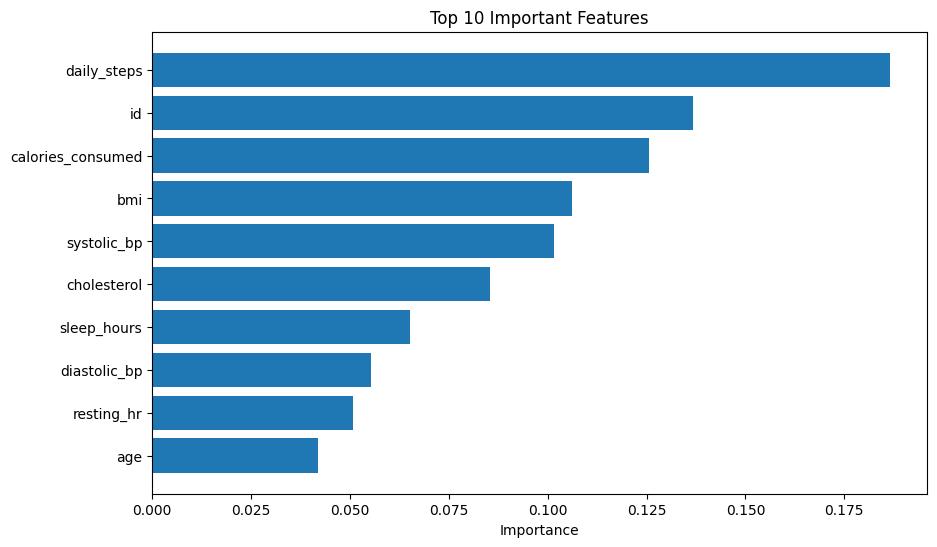

In [92]:
plt.figure(figsize=(10,6))

plt.barh(

importance["Feature"][:10],

importance["Importance"][:10]

)

plt.xlabel("Importance")

plt.title("Top 10 Important Features")

plt.gca().invert_yaxis()

plt.show()

In [93]:
!pip install shap -q

In [94]:
import shap

In [95]:
explainer = shap.Explainer(
    gb
)

shap_values = explainer(
    X_test
)

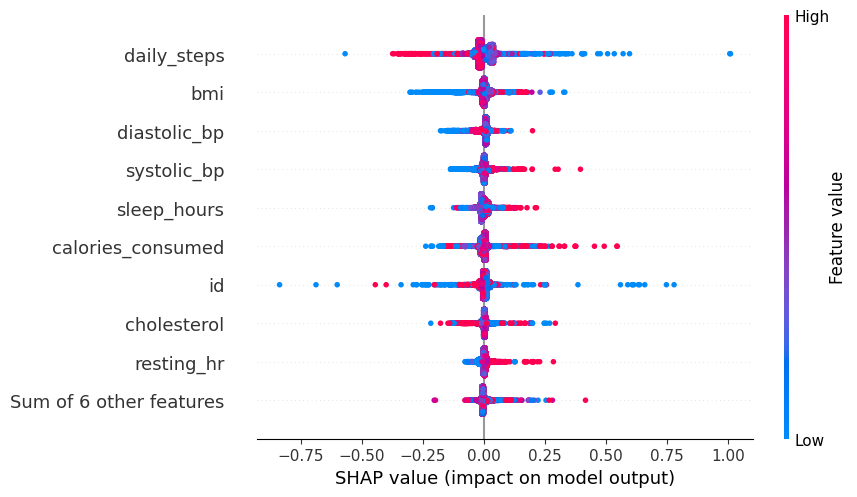

In [96]:
shap.plots.beeswarm(
    shap_values,
    max_display=10
)

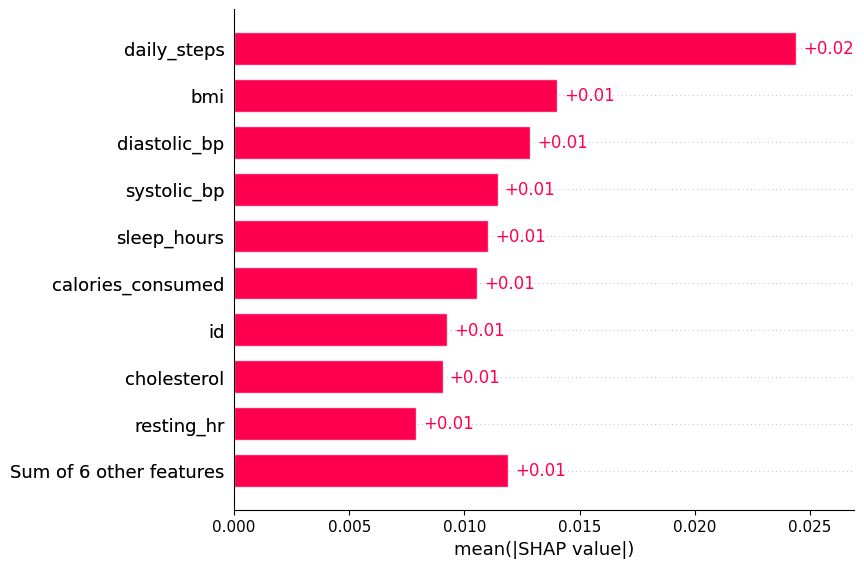

In [97]:
shap.plots.bar(
    shap_values,
    max_display=10
)

In [98]:
import joblib

joblib.dump(
    gb,
    "/content/drive/MyDrive/Lifestyle AI/Notebook/best_model.pkl"
)

print("Model Saved Successfully!")

Model Saved Successfully!


In [99]:
joblib.dump(

gender_encoder,

"/content/drive/MyDrive/Lifestyle AI/Notebook/gender_encoder.pkl"

)

joblib.dump(

target_encoder,

"/content/drive/MyDrive/Lifestyle AI/Notebook/target_encoder.pkl"

)

print("Encoders Saved!")

Encoders Saved!


In [100]:
results_df.to_csv(

"/content/drive/MyDrive/Lifestyle AI/Notebook/model_comparison.csv",

index=False

)

print("Comparison Table Saved!")

Comparison Table Saved!


In [101]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

models = {
    "Gradient Boosting": gb,
    "XGBoost": xgb,
    "CatBoost": cat,
    "Random Forest": rf,
    "Extra Trees Classifier": et,
    "MLP Classifier": mlp
}

results_table = []

for name, model in models.items():

    if name == "MLP Classifier":
        pred = model.predict(X_test_scaled)
    else:
        pred = model.predict(X_test)

    acc = accuracy_score(y_test, pred)
    prec = precision_score(y_test, pred, average='weighted')
    rec = recall_score(y_test, pred, average='weighted')
    f1 = f1_score(y_test, pred, average='weighted')

    results_table.append([
        name,
        round(acc * 100, 4),
        round(prec, 4),
        round(rec, 4),
        round(f1, 4)
    ])

import pandas as pd

results_df = pd.DataFrame(
    results_table,
    columns=[
        "Model",
        "Accuracy (%)",
        "Precision",
        "Recall",
        "F1-Score"
    ]
)

print(results_df)

results_df

                    Model  Accuracy (%)  Precision  Recall  F1-Score
0       Gradient Boosting        75.175     0.5652  0.7518    0.6453
1                 XGBoost        74.695     0.6227  0.7470    0.6467
2                CatBoost        75.145     0.6480  0.7514    0.6458
3           Random Forest        75.170     0.5652  0.7517    0.6452
4  Extra Trees Classifier        75.170     0.6273  0.7517    0.6453
5          MLP Classifier        75.105     0.5797  0.7510    0.6450


,Model,Accuracy (%),Precision,Recall,F1-Score
0,Gradient Boosting,75.175,0.5652,0.7518,0.6453
1,XGBoost,74.695,0.6227,0.7470,0.6467
2,CatBoost,75.145,0.6480,0.7514,0.6458
3,Random Forest,75.170,0.5652,0.7517,0.6452
4,Extra Trees Classifier,75.170,0.6273,0.7517,0.6453
5,MLP Classifier,75.105,0.5797,0.7510,0.6450
